# Predicting Next-Day Stock Direction (SPY)


## 1. Imports

In [83]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta_classic as ta

from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Download OHLCV Data


In [84]:
df = yf.download('SPY', start='2016-11-03', end='2026-11-03', interval='1d', auto_adjust=True)
df.columns = df.columns.get_level_values(0)   # ('Close','SPY') -> 'Close'
print(df.shape)
df.head()

[*********************100%***********************]  1 of 1 completed

(2512, 5)


Price,Close,High,Low,Open,Volume
Date,,,,,
2016-11-03,178.297165,179.544004,178.023893,179.330505,88939300
2016-11-04,178.100723,179.245074,177.955546,178.408162,109122100
2016-11-07,182.029083,182.063250,178.100713,178.100713,109794900
2016-11-08,182.848953,183.412593,181.371545,181.636281,106772100
2016-11-09,184.787506,185.402384,181.337358,181.362977,258429000


## 3. Data Checks and Descriptive Statistics

In [85]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate dates:', df.index.duplicated().sum())
print('Data Types:')
display(df.dtypes)
df.describe()

Missing values: 0
Duplicate dates: 0
Data Types:


Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Price,Close,High,Low,Open,Volume
count,2512.000000,2512.000000,2512.000000,2512.000000,2.512000e+03
mean,397.780373,399.835058,395.406281,397.719105,7.838621e+07
std,159.673754,160.291261,158.937225,159.667529,3.851316e+07
min,178.100723,179.245074,177.955546,178.100713,1.868500e+07
25%,255.949184,257.140896,254.316711,255.823601,5.503105e+07
50%,378.777390,381.846930,375.297760,379.005773,7.006700e+07
75%,504.228973,506.871573,500.526952,504.418964,9.081228e+07
max,779.090027,781.619995,777.960022,778.780029,3.922207e+08


## 4. Build ML Features 


In [86]:
# Moving averages (price units, only used to make the ratios below)
sma = df['Close'].rolling(20).mean()                  # simple moving average
ema = df['Close'].ewm(span=20, adjust=False).mean()   # exponential moving average

# VWAP over the last 20 days: sum(price*volume) / sum(volume) 
typical = (df['High'] + df['Low'] + df['Close']) / 3
vwap = (typical * df['Volume']).rolling(20).sum() / df['Volume'].rolling(20).sum()

# Features used by the model 
df['sma_dist']  = df['Close'] / sma  - 1    # how far price is above/below its SMA (0.02 = 2% above)
df['ema_dist']  = df['Close'] / ema  - 1
df['vwap_dist'] = df['Close'] / vwap - 1

df['rsi'] = ta.rsi(df['Close'], length=14)  # already 0-100, no scaling needed

macd = ta.macd(df['Close'])                 # returns a DataFrame with 3 columns
print(macd.columns.tolist())                # check names/order: line, histogram, signal
df['macd']      = macd.iloc[:, 0] / df['Close']   # MACD line, divided by price to make it scale-free
df['macd_hist'] = macd.iloc[:, 1] / df['Close']   # histogram 

df['ret_1d'] = df['Close'].pct_change()      # today's % change
df['ret_5d'] = df['Close'].pct_change(5)     # % change over 5 days
df['vol_20'] = df['ret_1d'].rolling(20).std()           # recent volatility
df['vol_rel'] = df['Volume'] / df['Volume'].rolling(20).mean()  # volume vs its 20-day average

df[['Close', 'sma_dist', 'rsi', 'macd_hist']].tail()

['MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9']


Price,Close,sma_dist,rsi,macd_hist
Date,,,,
2026-10-27,769.659973,-0.000975,51.319767,-0.001316
2026-10-28,772.309998,0.001835,53.537568,-0.000688
2026-10-29,769.359985,-0.002339,50.764935,-0.000516
2026-10-30,755.719971,-0.019142,40.357691,-0.001545
2026-11-02,752.099976,-0.022398,38.123878,-0.002425


## 5. Build the Target Variable


In [87]:
df['next_close'] = df['Close'].shift(-1)
df['target'] = (df['next_close'] > df['Close']).astype(int)   # 1 = up tomorrow, 0 = down
df['next_ret'] = df['Close'].pct_change().shift(-1)           # tomorrow's return (used only in the backtest)

df[['Close', 'next_close', 'target']].tail()   # last row has no tomorrow

Price,Close,next_close,target
Date,,,
2026-10-27,769.659973,772.309998,1
2026-10-28,772.309998,769.359985,0
2026-10-29,769.359985,755.719971,0
2026-10-30,755.719971,752.099976,0
2026-11-02,752.099976,NaN,0


In [88]:
# The last row has no tomorrow, and around the first 20 rows have NaN indicators. Drop them.
df = df.iloc[:-1]
df = df.dropna()
print(df.shape)
print('Share of up days:', round(df['target'].mean(), 3))

(2478, 18)
Share of up days: 0.552


## 6. Chronological train/test split (80/20)
No shuffling: train on the older 80%, test on the newest 20%. 

In [89]:
feature_cols = ['sma_dist', 'ema_dist', 'vwap_dist', 'rsi', 'macd', 'macd_hist',
                'ret_1d', 'ret_5d', 'vol_20', 'vol_rel']

split = int(len(df) * 0.8)
train = df.iloc[:split]
test  = df.iloc[split:]

X_train, y_train = train[feature_cols], train['target']
X_test,  y_test  = test[feature_cols],  test['target']

print('Train:', train.index.min().date(), 'to', train.index.max().date(), len(train), 'rows')
print('Test: ', test.index.min().date(),  'to', test.index.max().date(),  len(test),  'rows')

# Scaled copies for logistic regression 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)     

# Share of up days in the test set
print('Share of up days:', round(test['target'].mean(), 3))

Train: 2016-12-21 to 2024-11-06 1982 rows
Test:  2024-11-07 to 2026-10-30 496 rows
Share of up days: 0.546


## 7. Models
- **Baseline**: always predicts the most common class (the 'always up' guess). Every model has to beat this, not 50%.
- Logistic regression uses the scaled data. The tree models use the unscaled data.

In [90]:
# Baseline
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

# Logistic Regression
logit = LogisticRegression(max_iter=1000, random_state=42)
logit.fit(X_train_scaled, y_train)
logit_pred = logit.predict(X_test_scaled)

# Random Forest
forest = RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=50, random_state=42)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

# Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

# Predictions 
predictions = {
    'Baseline (always up)': base_pred,
    'Logistic Regression': logit_pred,
    'Random Forest': forest_pred,
    'Gradient Boosting': gb_pred,
}

## 8. Evaluate
Remember the test set's share of up days is the number to beat. Differences of 1-2 points are within noise.

In [91]:
rows = []
for name, pred in predictions.items():
    rows.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0),
        '% days predicted up': pred.mean(),
    })
results_df = pd.DataFrame(rows).round(3)
print('Test share of up days (baseline accuracy):', round(y_test.mean(), 3))
display(results_df)

Test share of up days (baseline accuracy): 0.546


,Algorithm,Accuracy,Precision,Recall,F1 Score,% days predicted up
0,Baseline (always up),0.546,0.546,1.000,0.707,1.000
1,Logistic Regression,0.532,0.542,0.937,0.686,0.946
2,Random Forest,0.526,0.540,0.900,0.675,0.911
3,Gradient Boosting,0.510,0.533,0.845,0.653,0.867


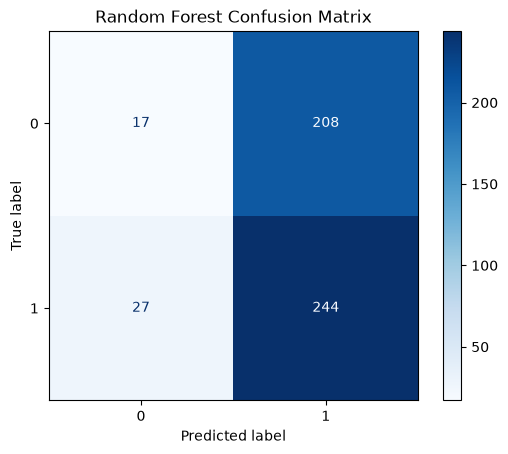

In [92]:
# Confusion matrix for one model (rows = actual, columns = predicted; 0 = down, 1 = up)
cm = confusion_matrix(y_test, forest_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)  # may need to add labels
disp.plot(cmap=plt.cm.Blues)
plt.title('Random Forest Confusion Matrix')
plt.show()

#print(confusion_matrix(y_test, forest_pred))

## 9. Backtest
The signal is made at today's close and earns tomorrow's return (next_ret). If the model says 1, we hold the stock; if 0, we sit in cash. The fee is charged whenever the position changes.

In [93]:
cost = 0.0005   # 0.05% per trade; try 0 and 0.001 too

def backtest(pred):
    signal = pd.Series(pred, index=test.index)
    trades = signal.diff().abs().fillna(signal.abs())   # 1 on days the position changes
    return signal * test['next_ret'] - trades * cost    # daily strategy return

def metrics(r):
    equity = (1 + r).cumprod()
    years = len(r) / 252
    return {
        'Cumulative return': equity.iloc[-1] - 1,
        'Sharpe': r.mean() / r.std() * np.sqrt(252),
        'Max drawdown': (equity / equity.cummax() - 1).min(),
    }

curves = {'Buy & Hold': test['next_ret']}
for name, pred in predictions.items():
    if name.startswith('Baseline'):
        continue
    curves[name] = backtest(pred)

bt = pd.DataFrame({name: metrics(r) for name, r in curves.items()}).T.round(3)
bt['% days invested'] = [1.0] + [predictions[n].mean() for n in curves if n != 'Buy & Hold']
bt

,Cumulative return,Sharpe,Max drawdown,% days invested
Buy & Hold,0.292,0.870,-0.188,1.000000
Logistic Regression,0.314,0.959,-0.177,0.945565
Random Forest,0.184,0.623,-0.197,0.911290
Gradient Boosting,-0.023,-0.018,-0.259,0.866935


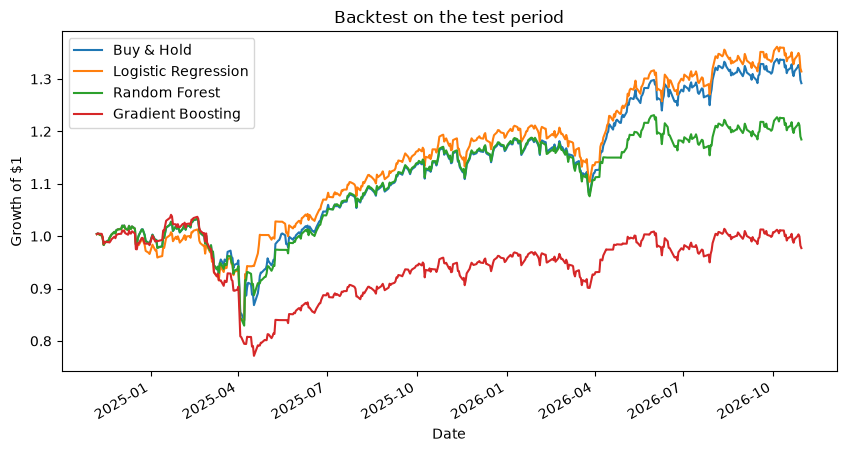

In [94]:
# Plot Backtest Graph
plt.figure(figsize=(10, 5))
for name, r in curves.items():
    (1 + r).cumprod().plot(label=name)
plt.ylabel('Growth of $1')
plt.title('Backtest on the test period')
plt.legend()
plt.show()